<a href="https://colab.research.google.com/github/RoqueThis/MachineLearning/blob/main/Copy_of_starter_signs_v2_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Note: After you run this cell, the training and test data will be available in
# the file browser. (Click the folder icon on the left to view it)
#
# If you don't see the data after the cell completes, click the refresh button
# in the file browser (folder icon with circular arrow)

# First, let's download and unzip the data
!echo "Downloading files..."
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/training1.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/training2.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/holdout.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/mini_holdout.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/mini_holdout_answers.csv

!echo "Unzipping files..."
!unzip -q /content/training1.zip
!unzip -q /content/training2.zip
!unzip -q /content/holdout.zip
!unzip -q /content/mini_holdout.zip

# Combine the two traning directories
!echo "Merging training data..."
!mkdir /content/training
!mv /content/training1/* /content/training
!mv /content/training2/* /content/training

# Cleanup
!echo "Cleaning up..."
!rmdir /content/training1
!rmdir /content/training2
!rm training1.zip
!rm training2.zip
!rm holdout.zip
!rm mini_holdout.zip

!echo "Data ready."

Unzipping files...
Merging training data...
Cleaning up...
Data ready.


In [ ]:
# Import libraries
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# We're using keras' ImageDataGenerator class to load our image data.
# See (https://keras.io/api/preprocessing/image/#imagedatagenerator-class) for details
#
# A couple of things to note:
# 1. We're specifying a number for the seed, so we'll always get the same shuffle and split of our images.
# 2. Class names are inferred automatically from the image subdirectory names.
# 3. We're splitting the training data into 80% training, 20% validation.


training_dir = '/content/training/'
image_size = (100, 100)

# Split up the training data images into training and validations sets
# We'll use and ImageDataGenerator to do the splits
# ImageDataGenerator can also be used to do preprocessing and agumentation on the files as can be seen with rescale

train_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=.2
        )
validation_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=.2
        )

train_generator = train_datagen.flow_from_directory(
        training_dir,
        target_size = image_size,
        subset="training",
        batch_size=32,
        class_mode='sparse',
        seed=42,shuffle=True)
validation_generator = validation_datagen.flow_from_directory(
        training_dir,
        target_size=image_size,
        batch_size=32,
        class_mode='sparse',
        subset="validation",
        seed=42)




Found 31368 images belonging to 43 classes.
Found 7841 images belonging to 43 classes.


In [ ]:

def gaussian_blur(image):
    sigma = tf.random.uniform([], 0.3, 2.0)

    x = tf.range(-2, 3, dtype=tf.float32)
    kernel_1d = tf.exp(-(x ** 2) / (2 * sigma ** 2))
    kernel_1d /= tf.reduce_sum(kernel_1d)

    kernel_2d = tf.tensordot(
        kernel_1d, kernel_1d, axes=0
    )

    kernel = tf.tile(
        kernel_2d[:, :, None, None],
        [1, 1, 3, 1]
    )

    return tf.nn.depthwise_conv2d(
        image[None, ...],
        kernel,
        strides=[1, 1, 1, 1],
        padding="SAME"
    )[0]


def color_adjust(image):
    image = tf.image.random_brightness(image, 0.2)
    image = tf.image.random_contrast(image, 0.6, 1.4)
    image = tf.image.random_saturation(image, 0.6, 1.4)
    image = tf.image.random_hue(image, 0.08)

    return tf.clip_by_value(image, 0.0, 1.0)


def gamma_adjust(image):
    gamma = tf.random.uniform([], 0.5, 1.8)

    return tf.image.adjust_gamma(image, gamma)


def gaussian_noise(image):
    stddev = tf.random.uniform([], 0.01, 0.12)

    noise = tf.random.normal(
        tf.shape(image),
        mean=0.0,
        stddev=stddev
    )

    return tf.clip_by_value(image + noise, 0.0, 1.0)


def salt_pepper_noise(image):
    probability = tf.random.uniform([], 0.005, 0.04)

    random_values = tf.random.uniform(tf.shape(image))

    image = tf.where(
        random_values < probability / 2,
        0.0,
        image
    )

    image = tf.where(
        random_values > 1.0 - probability / 2,
        1.0,
        image
    )

    return image


def random_occlusion(image):
    shape = tf.shape(image)
    height, width = shape[0], shape[1]

    cut_h = tf.random.uniform(
        [], 0.1, 0.4
    ) * tf.cast(height, tf.float32)

    cut_w = tf.random.uniform(
        [], 0.1, 0.4
    ) * tf.cast(width, tf.float32)

    cy = tf.random.uniform(
        [], 0, tf.cast(height, tf.float32)
    )

    cx = tf.random.uniform(
        [], 0, tf.cast(width, tf.float32)
    )

    yy, xx = tf.meshgrid(
        tf.range(height),
        tf.range(width),
        indexing="ij"
    )

    mask = (
        (tf.abs(tf.cast(yy, tf.float32) - cy) < cut_h / 2) &
        (tf.abs(tf.cast(xx, tf.float32) - cx) < cut_w / 2)
    )

    # Replace the missing region with the image mean.
    fill = tf.reduce_mean(image, axis=[0, 1])

    return tf.where(
        mask[..., None],
        fill[None, None, :],
        image
    )


def geometric_transform(image):
    shape = tf.shape(image)
    height = shape[0]
    width = shape[1]

    angle = tf.random.uniform([], -0.2, 0.2)
    scale = tf.random.uniform([], 0.85, 1.15)

    tx = tf.random.uniform([], -0.1, 0.1) * tf.cast(width, tf.float32)
    ty = tf.random.uniform([], -0.1, 0.1) * tf.cast(height, tf.float32)

    cos_a = tf.cos(angle) / scale
    sin_a = tf.sin(angle) / scale

    cx = tf.cast(width, tf.float32) / 2
    cy = tf.cast(height, tf.float32) / 2

    # Output-to-input projective transformation.
    transform = tf.stack([
        cos_a,
        sin_a,
        cx - cos_a * cx - sin_a * cy - tx,
        -sin_a,
        cos_a,
        cy + sin_a * cx - cos_a * cy - ty,
        0.0,
        0.0
    ])

    transformed = tf.raw_ops.ImageProjectiveTransformV3(
        images=image[None, ...],
        transforms=transform[None, ...],
        output_shape=shape[:2],
        interpolation="BILINEAR",
        fill_mode="REFLECT",
        fill_value=0.0
    )

    return transformed[0]


def horizontal_flip(image):
    return tf.image.random_flip_left_right(image)


def vertical_flip(image):
    return tf.image.random_flip_up_down(image)


def augment_image(image, min_augmentations=1, max_augmentations=4):
    """
    Randomly selects a subset of augmentation operations.
    Each selected operation is applied at most once.
    """

    operations = [
        gaussian_blur,
        color_adjust,
        gamma_adjust,
        gaussian_noise,
        salt_pepper_noise,
        random_occlusion,
        geometric_transform,
        horizontal_flip,
        vertical_flip
    ]

    num_operations = len(operations)

    # Randomly choose how many transformations to apply.
    count = tf.random.uniform(
        [],
        min_augmentations,
        max_augmentations + 1,
        dtype=tf.int32
    )

    # Shuffle operation indices to avoid always applying
    # transformations in the same order.
    indices = tf.random.shuffle(
        tf.range(num_operations)
    )[:count]

    def condition(i, img):
        return i < count

    def body(i, img):
        img = tf.switch_case(
            indices[i],
            branch_fns=operations
        )
        return i + 1, img

    _, image = tf.while_loop(
        condition,
        body,
        (tf.constant(0), image)
    )

    return tf.clip_by_value(image, 0.0, 1.0)


def expand_dataset(
    dataset,
    copies_per_image=4,
    min_augmentations=1,
    max_augmentations=4,
    seed=None
):
    """
    Expands an unbatched (image, label) tf.data.Dataset.

    Original image is retained, followed by randomized copies.

    Returns an unbatched dataset.
    """

    if seed is not None:
        tf.random.set_seed(seed)

    def expand(image, label):
        augmented_images = [
            image
        ]

        for _ in range(copies_per_image):
            augmented_images.append(
                augment_image(
                    image,
                    min_augmentations,
                    max_augmentations
                )
            )

        images = tf.stack(augmented_images)

        labels = tf.repeat(
            tf.expand_dims(label, axis=0),
            copies_per_image + 1,
            axis=0
        )

        return tf.data.Dataset.from_tensor_slices(
            (images, labels)
        )

    return dataset.flat_map(expand)


In [ ]:
#these might come in handy
target_names = ['Speed_20', 'Speed_30', 'Speed_50', 'Speed_60', 'Speed_70',
               'Speed_80','Speed_Limit_Ends', 'Speed_100', 'Speed_120', 'Overtaking_Prohibited',
               'Overtakeing_Prohibited_Trucks', 'Priority', 'Priority_Road_Ahead', 'Yield', 'STOP',
               'Entry_Forbidden', 'Trucks_Forbidden', 'No_Entry(one-way traffic)', 'General Danger(!)', 'Left_Curve_Ahead',
               'Right_Curve_Ahead', 'Double_Curve', 'Poor_Surface_Ahead', 'Slippery_Surface_Ahead', 'Road_Narrows_On_Right',
               'Roadwork_Ahead', 'Traffic_Light_Ahead', 'Warning_Pedestrians', 'Warning_Children', 'Warning_Bikes',
               'Ice_Snow', 'Deer_Crossing', 'End_Previous_Limitation', 'Turning_Right_Compulsory', 'Turning_Left_Compulsory',
               'Ahead_Only', 'Straight_Or_Right_Mandatory', 'Straight_Or_Left_Mandatory', 'Passing_Right_Compulsory', 'Passing_Left_Compulsory',
               'Roundabout', 'End_Overtaking_Prohibition', 'End_Overtaking_Prohibition_Trucks']

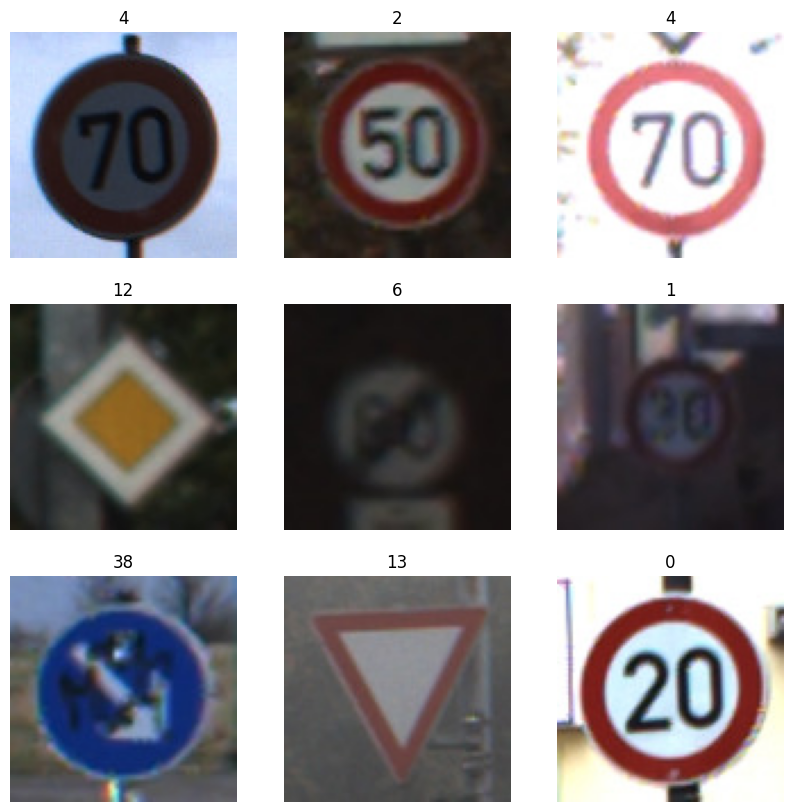

In [ ]:
# View 9 images and their class labels
plt.figure(figsize=(10, 10))
images, labels = next(train_generator)  # Assuming train_generator is a generator
batch_size = images.shape[0]

for i in range(min(9, batch_size)):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow((images[i] * 255).astype("uint8"))
    plt.title(int(labels[i]))
    plt.axis("off")

plt.show()

In [ ]:
road_sign_model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(100, 100, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(128, activation='relu'),
    layers.Dense(43, activation='softmax')
])



road_sign_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Training model on road signs dataset...")
history = road_sign_model.fit(
    train_generator,
    epochs=5,
    validation_data=validation_generator
)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training model on road signs dataset...
Epoch 1/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 54s 45ms/step - accuracy: 0.7889 - loss: 0.7424 - val_accuracy: 0.8560 - val_loss: 0.5859
Epoch 2/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 29s 30ms/step - accuracy: 0.9759 - loss: 0.0898 - val_accuracy: 0.9010 - val_loss: 0.3790
Epoch 3/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 29s 30ms/step - accuracy: 0.9864 - loss: 0.0496 - val_accuracy: 0.9214 - val_loss: 0.3779
Epoch 4/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 31s 31ms/step - accuracy: 0.9887 - loss: 0.0385 - val_accuracy: 0.9149 - val_loss: 0.3437
Epoch 5/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 30s 31ms/step - accuracy: 0.9930 - loss: 0.0249 - val_accuracy: 0.9263 - val_loss: 0.3648


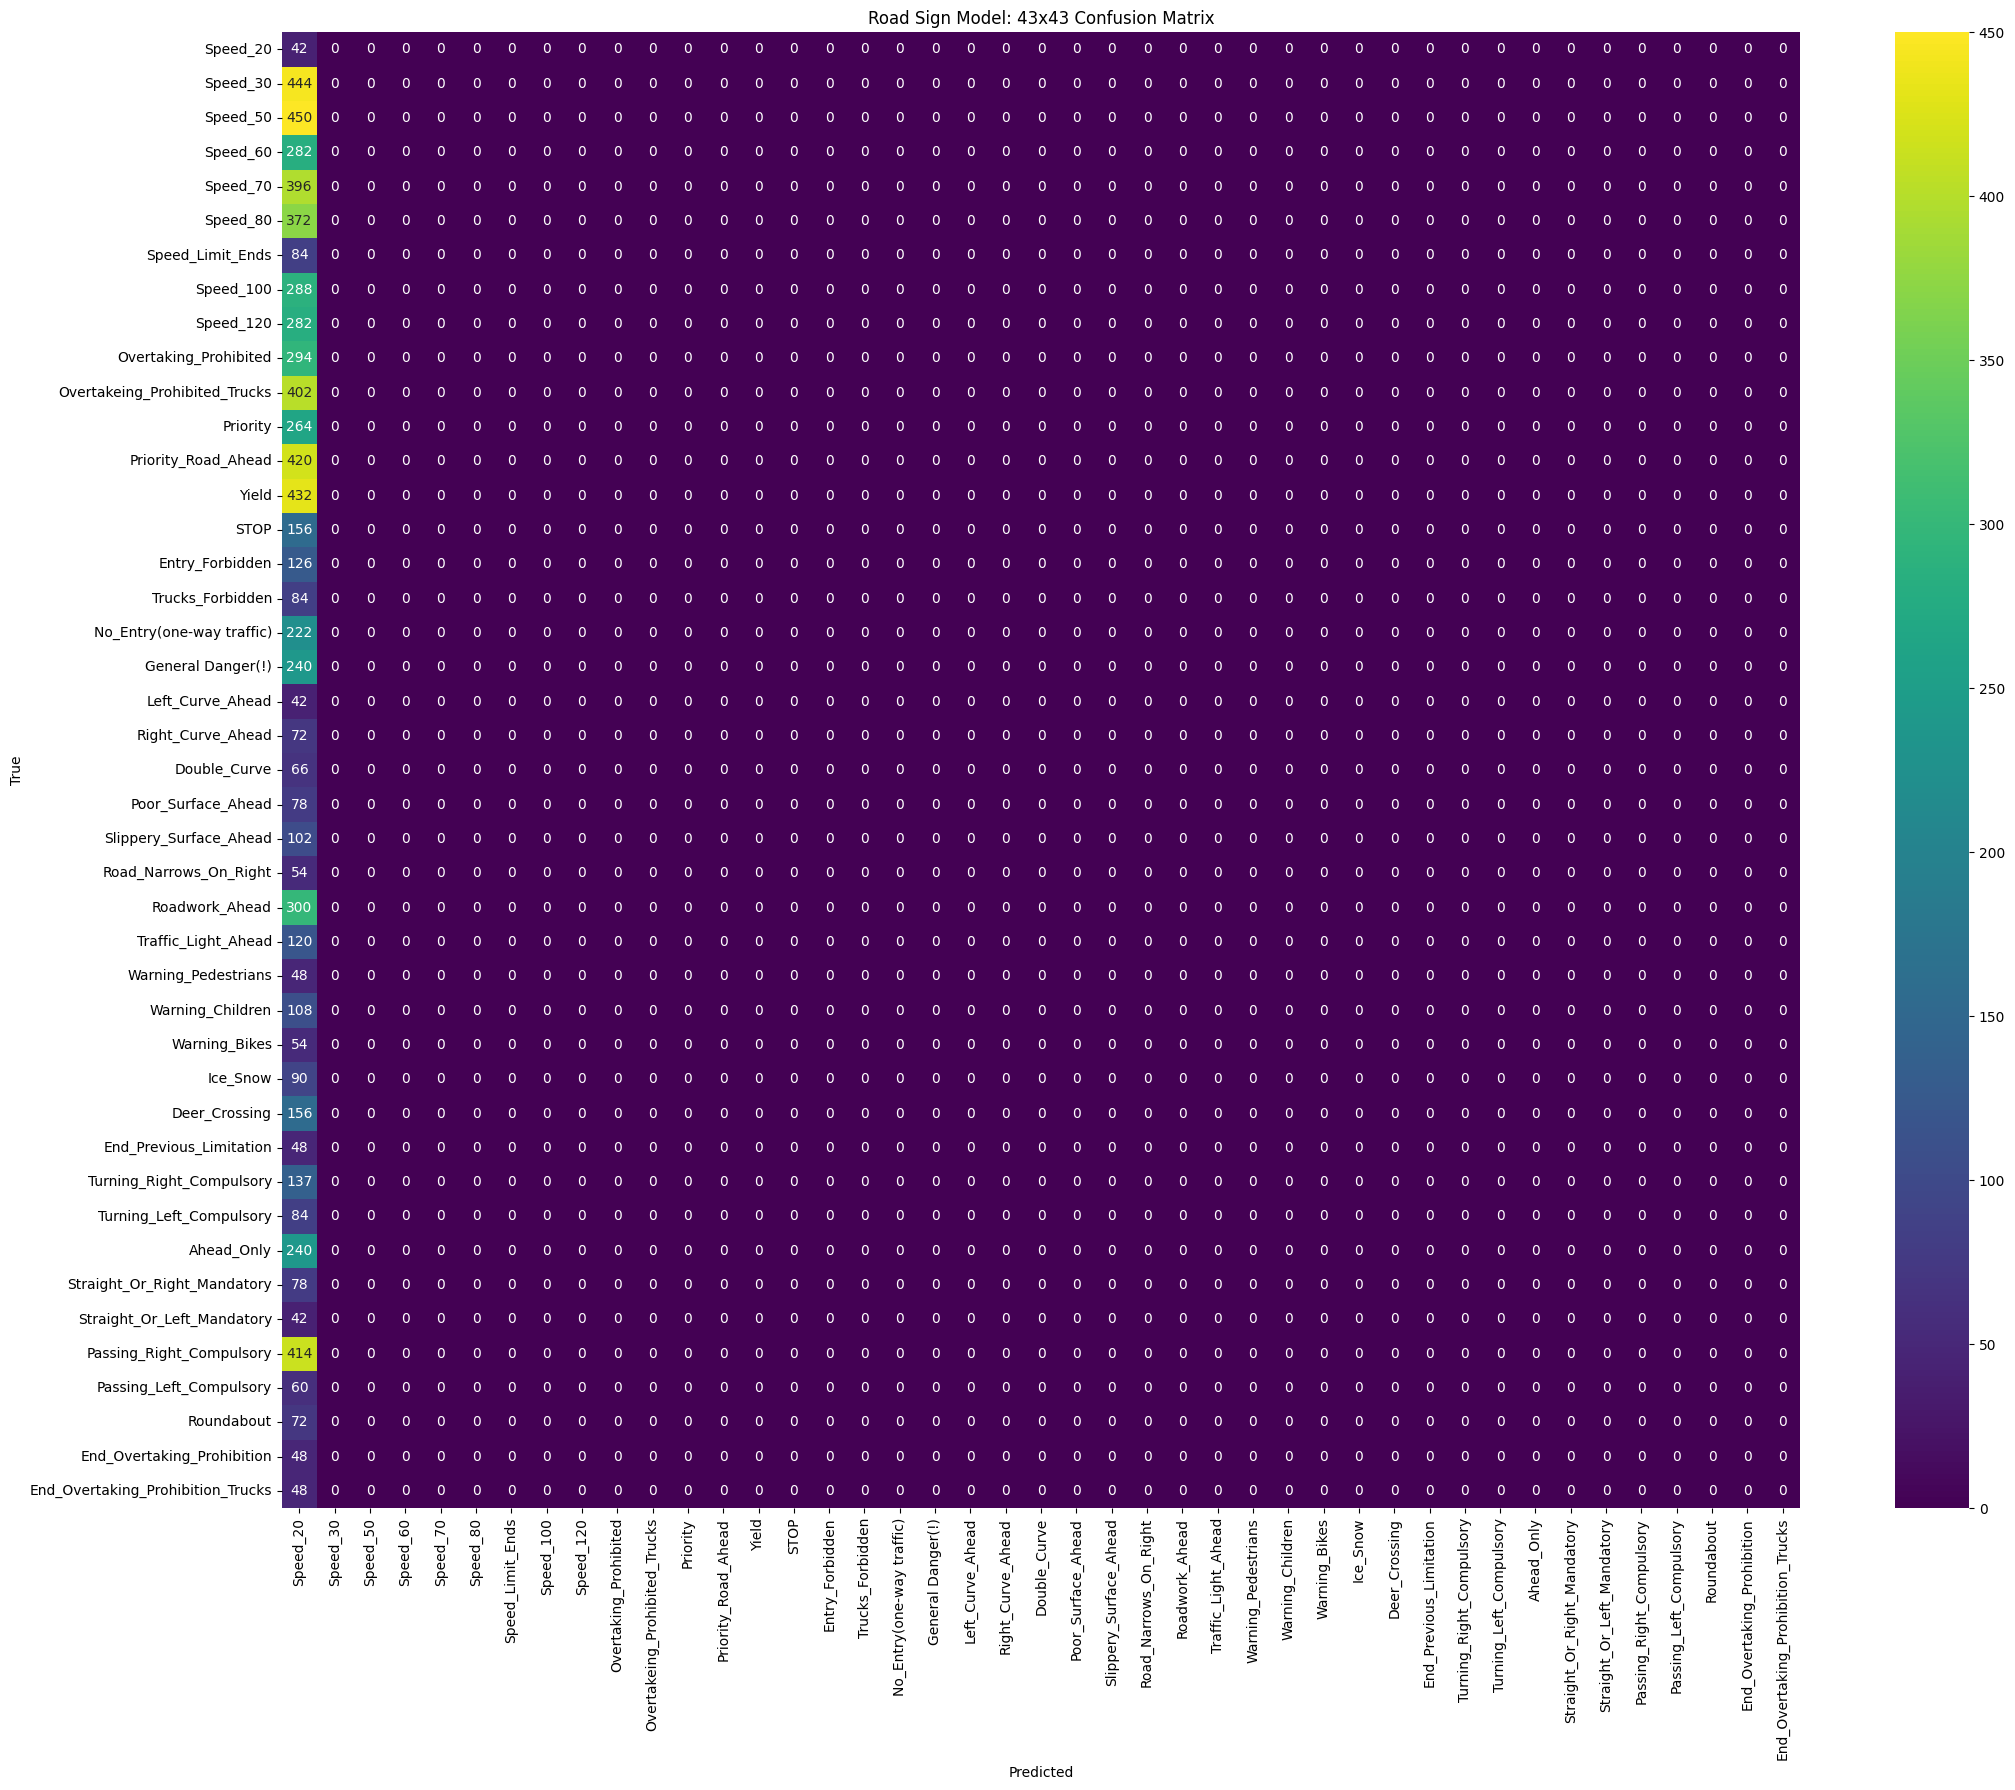

In [ ]:
validation_generator.reset()

all_preds = []
all_trues = []

for i in range(len(validation_generator)):
    imgs, labels = next(validation_generator)
    preds = road_sign_model.predict(imgs, verbose=0).argmax(axis=1)
    all_preds.extend(preds)
    all_trues.extend(labels)

y_true = np.array(all_trues)
y_pred = np.array(all_preds)

cm = confusion_matrix(y_true, y_pred, labels=list(range(43)))

plt.figure(figsize=(22, 18))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=target_names,
    yticklabels=target_names,
    cmap='viridis'
)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Road Sign Model: 43x43 Confusion Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Save the trained model
road_sign_model.save('cnn_sign_model.h5')

# Load the model when needed
#from tensorflow.keras.models import load_model
#model = load_model('cnn_sign_model.h5')

In [ ]:
from tensorflow.keras.preprocessing import image_dataset_from_directory
test_dir = '/content/'

test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
        test_dir,
        classes=['mini_holdout'],
        target_size=image_size,
        class_mode='sparse',
        shuffle=False)
probabilities = road_sign_model.predict(test_generator)
predictions = [np.argmax(probas) for probas in probabilities]

Found 201 images belonging to 1 classes.
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 406ms/step


In [ ]:
from tensorflow.keras.preprocessing import image_dataset_from_directory
test_dir = '/content/'
image_size = (100, 100)

test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
        test_dir,
        classes=['holdout'],
        target_size=image_size,
        class_mode='sparse',
        shuffle=False)
probabilities = road_sign_model.predict(test_generator)
predictions = [np.argmax(probas) for probas in probabilities]




Found 12630 images belonging to 1 classes.
395/395 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step


In [ ]:
model = load_model('cnn_sign_model.h5')



## Testing the model
Once you have built and trained your model, the next step is to run the mini holdout images through it and see how well your model does at making predictions for images it has never seen before.

Since loading these images and formatting them for the model can be tricky, you may find the following code useful. This code only uses your model to predict the class label for a given image. You'll still need to compare those predictions to the "ground truth" class labels in `mini_holdout_answers.csv` to evaluate how well the model does.

Previously, you were given a file that would check your results. This time you're given the answers to the first mini holdout dataset. You'll need to compare those predictions against the "ground truth" class labels in `mini_holdout_answers.csv` to evaluate how well the model does.

Make sure to use the insights gained from the mini hold out dataset in your executive summary.


```
from tensorflow.keras.preprocessing import image_dataset_from_directory
test_dir = '/content/'

test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
        test_dir,
        classes=['mini_holdout'],
        target_size=image_size,
        class_mode='sparse',
        shuffle=False)
probabilities = model.predict(test_generator)
predictions = [np.argmax(probas) for probas in probabilities]
```



##Mini Hold out Dataset


Once you feel confident, you will need to predict for the full holdout dataset using the following code, and submit your csv file:

```
from tensorflow.keras.preprocessing import image_dataset_from_directory
test_dir = '/content/'

test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
        test_dir,
        classes=['holdout'],
        target_size=image_size,
        class_mode='sparse',
        shuffle=False)
probabilities = model.predict(test_generator)
predictions = [np.argmax(probas) for probas in probabilities]
```